# Human Activity Recognition: Dimensionality Reduction

**Question:** Can 561 smartphone-sensor features be compressed into a smaller representation that still reveals meaningful activity structure?

**Methods:** PCA, t-SNE, and UMAP. **Rule:** activity labels are used only after fitting, as an interpretation reference.

## 1. Setup

A fixed seed makes experiments reproducible. Fixed colours give each activity the same meaning in every chart.

In [1]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

ACTIVITY_ORDER = ["STANDING", "SITTING", "LAYING", "WALKING", "WALKING_DOWNSTAIRS", "WALKING_UPSTAIRS"]
ACTIVITY_COLORS = dict(zip(ACTIVITY_ORDER, ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]))

print(f"pandas: {pd.__version__}")
print(f"numpy: {np.__version__}")
print(f"scikit-learn: {sklearn.__version__}")

pandas: 2.3.3
numpy: 2.5.3
scikit-learn: 1.9.1


## 2. Audit and preprocessing

Each row is a short window of phone motion. `subject` identifies a person and `Activity` is the answer key, so both are excluded from the 561-feature matrix. No feature values are missing.

`StandardScaler` is fitted on training data only. This makes variance- and distance-based methods treat every sensor feature fairly.

In [2]:
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("data")
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

ID_COLUMN, REFERENCE_COLUMN = "subject", "Activity"
feature_columns = train_df.columns.drop([ID_COLUMN, REFERENCE_COLUMN]).tolist()
X_train_raw, X_test_raw = train_df[feature_columns], test_df[feature_columns]
y_train_reference, y_test_reference = train_df[REFERENCE_COLUMN], test_df[REFERENCE_COLUMN]

assert train_df.columns.equals(test_df.columns)
assert len(feature_columns) == 561
assert X_train_raw.isna().sum().sum() == X_test_raw.isna().sum().sum() == 0

scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train_raw), columns=feature_columns, index=X_train_raw.index)
X_test = pd.DataFrame(scaler.transform(X_test_raw), columns=feature_columns, index=X_test_raw.index)
assert np.allclose(X_train.mean(), 0) and np.allclose(X_train.std(ddof=0), 1)

display(pd.DataFrame({"dataset": ["train", "test"], "rows": [len(train_df), len(test_df)], "sensor_features": [len(feature_columns)] * 2}))
print(f"Exact duplicate training rows: {train_df.duplicated().sum():,}")
display(y_train_reference.value_counts().rename_axis("activity").to_frame("training_rows"))

,dataset,rows,sensor_features
0,train,7352,561
1,test,2947,561


Exact duplicate training rows: 0


,training_rows
activity,
LAYING,1407
STANDING,1374
SITTING,1286
WALKING,1226
WALKING_UPSTAIRS,1073
WALKING_DOWNSTAIRS,986


## 3. PCA: reusable linear compression

PCA learns reusable directions of variation, so it can transform new recordings. We select 95% explained variance for compression. The 2D map is only for human inspection; it necessarily loses information.

,retained_variance,components_needed
0,80%,26
1,90%,63
2,95%,102
3,99%,179


Selected compression: 102 components retain 95.08%.
The 2D PCA map shows 57.36% of variance.


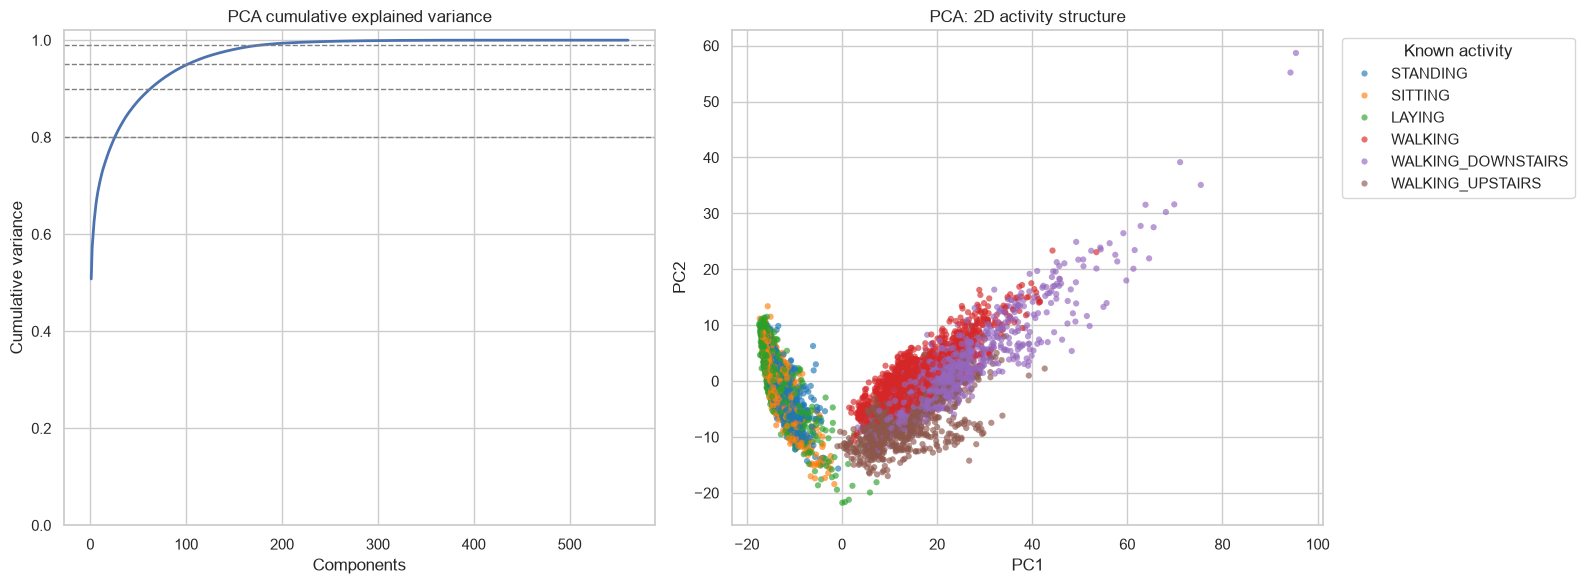

In [3]:
from sklearn.decomposition import PCA

pca_full = PCA().fit(X_train)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
targets = [0.80, 0.90, 0.95, 0.99]
components_needed = {f"{int(target * 100)}%": int(np.argmax(cumulative_variance >= target) + 1) for target in targets}

pca_95 = PCA(n_components=0.95)
X_train_pca_95 = pca_95.fit_transform(X_train)
X_test_pca_95 = pca_95.transform(X_test)
pca_2d = PCA(n_components=2)
X_train_pca_2d = pca_2d.fit_transform(X_train)
pca_2d_variance = pca_2d.explained_variance_ratio_.sum()

display(pd.DataFrame({"retained_variance": components_needed.keys(), "components_needed": components_needed.values()}))
print(f"Selected compression: {pca_95.n_components_} components retain {pca_95.explained_variance_ratio_.sum():.2%}.")
print(f"The 2D PCA map shows {pca_2d_variance:.2%} of variance.")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].plot(range(1, len(cumulative_variance) + 1), cumulative_variance, linewidth=2)
for target in targets: axes[0].axhline(target, color="gray", linestyle="--", linewidth=1)
axes[0].set(title="PCA cumulative explained variance", xlabel="Components", ylabel="Cumulative variance", ylim=(0, 1.02))
pca_plot = pd.DataFrame(X_train_pca_2d, columns=["PC1", "PC2"]).assign(Activity=y_train_reference.values)
sns.scatterplot(data=pca_plot, x="PC1", y="PC2", hue="Activity", hue_order=ACTIVITY_ORDER, palette=ACTIVITY_COLORS, alpha=.65, s=20, linewidth=0, ax=axes[1])
axes[1].set_title("PCA: 2D activity structure")
axes[1].legend(title="Known activity", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

## 4. t-SNE: local neighbourhood structure

t-SNE is a visualisation rather than a reusable compressor. It is tuned without labels on a fixed sample using **trustworthiness**: whether close 2D neighbours were genuinely close in the original feature space. A second seed checks that the selected setting is stable.

Parameter search:


,perplexity,trustworthiness
4,75,0.9737
3,50,0.9733
2,30,0.9727
1,15,0.9721
0,5,0.9653


Selected-setting stability:


,perplexity,seed,trustworthiness
0,75,42,0.9737
1,75,7,0.9740


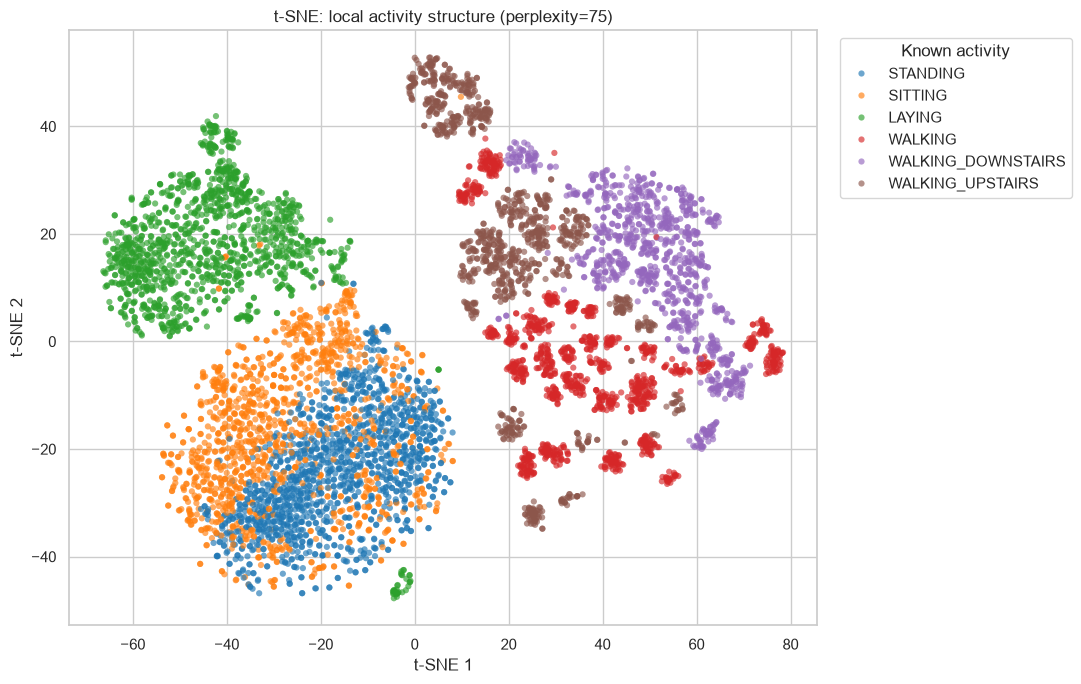

In [4]:
from sklearn.manifold import TSNE, trustworthiness

SEARCH_SAMPLE_SIZE = 3_000
search_indices = np.random.RandomState(RANDOM_STATE).choice(len(X_train), size=SEARCH_SAMPLE_SIZE, replace=False)
X_search = X_train.iloc[search_indices]

def tsne_embedding(perplexity, seed):
    return TSNE(n_components=2, perplexity=perplexity, learning_rate="auto", init="pca", max_iter=1_000, random_state=seed).fit_transform(X_search)

tsne_rows = []
for perplexity in [5, 15, 30, 50, 75]:
    embedding = tsne_embedding(perplexity, RANDOM_STATE)
    tsne_rows.append({"perplexity": perplexity, "trustworthiness": trustworthiness(X_search, embedding, n_neighbors=10)})
tsne_search_df = pd.DataFrame(tsne_rows).sort_values("trustworthiness", ascending=False)
SELECTED_PERPLEXITY = int(tsne_search_df.iloc[0].perplexity)

stability_rows = []
for seed in [RANDOM_STATE, 7]:
    embedding = tsne_embedding(SELECTED_PERPLEXITY, seed)
    stability_rows.append({"perplexity": SELECTED_PERPLEXITY, "seed": seed, "trustworthiness": trustworthiness(X_search, embedding, n_neighbors=10)})
tsne_stability_df = pd.DataFrame(stability_rows)

print("Parameter search:"); display(tsne_search_df.round(4))
print("Selected-setting stability:"); display(tsne_stability_df.round(4))

tsne_final = TSNE(n_components=2, perplexity=SELECTED_PERPLEXITY, learning_rate="auto", init="pca", max_iter=1_000, random_state=RANDOM_STATE)
X_train_tsne = tsne_final.fit_transform(X_train)
tsne_plot = pd.DataFrame(X_train_tsne, columns=["t-SNE 1", "t-SNE 2"]).assign(Activity=y_train_reference.values)
plt.figure(figsize=(11, 7))
sns.scatterplot(data=tsne_plot, x="t-SNE 1", y="t-SNE 2", hue="Activity", hue_order=ACTIVITY_ORDER, palette=ACTIVITY_COLORS, alpha=.65, s=20, linewidth=0)
plt.title(f"t-SNE: local activity structure (perplexity={SELECTED_PERPLEXITY})")
plt.legend(title="Known activity", bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

## 5. UMAP: local structure for unseen data

UMAP is tuned with the same label-free sample and trustworthiness criterion. Unlike t-SNE, it can transform new data. The selected map is fitted on training recordings and evaluated by placing held-out test recordings into it.

Neighbourhood-size search:


,n_neighbors,trustworthiness
0,5,0.9597
1,15,0.9565
2,30,0.9547
3,50,0.9496


Minimum-distance search:


,min_dist,trustworthiness
0,0.0,0.9632
1,0.1,0.9597
2,0.3,0.9557
3,0.5,0.9510


Held-out test-set check:


,seed,test_trustworthiness
0,42,0.9163
1,7,0.9163


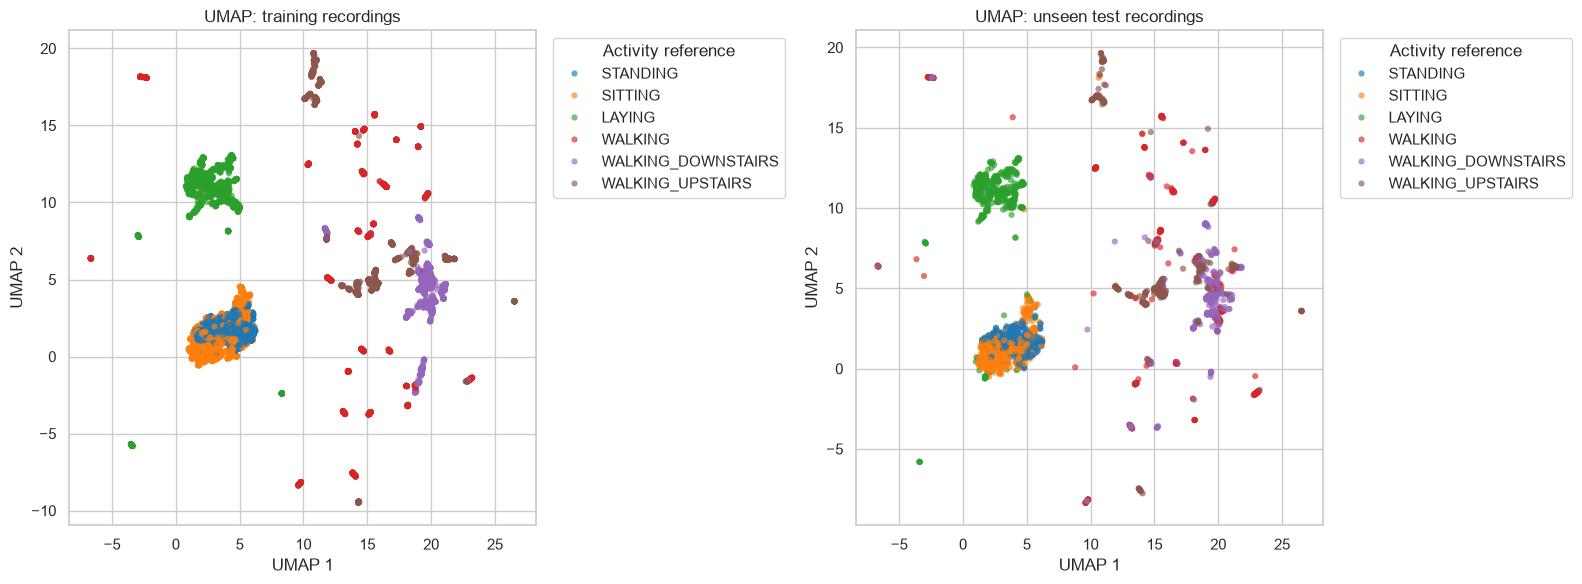

In [5]:
import umap.umap_ as umap

def umap_embedding(n_neighbors, min_dist, data, seed):
    return umap.UMAP(n_components=2, n_neighbors=n_neighbors, min_dist=min_dist, metric="euclidean", n_jobs=1, random_state=seed).fit_transform(data)

neighbor_rows = []
for n_neighbors in [5, 15, 30, 50]:
    embedding = umap_embedding(n_neighbors, .1, X_search, RANDOM_STATE)
    neighbor_rows.append({"n_neighbors": n_neighbors, "trustworthiness": trustworthiness(X_search, embedding, n_neighbors=10)})
neighbors_df = pd.DataFrame(neighbor_rows).sort_values("trustworthiness", ascending=False)
SELECTED_NEIGHBORS = int(neighbors_df.iloc[0].n_neighbors)

min_dist_rows = []
for min_dist in [0.0, 0.1, 0.3, 0.5]:
    embedding = umap_embedding(SELECTED_NEIGHBORS, min_dist, X_search, RANDOM_STATE)
    min_dist_rows.append({"min_dist": min_dist, "trustworthiness": trustworthiness(X_search, embedding, n_neighbors=10)})
min_dist_df = pd.DataFrame(min_dist_rows).sort_values("trustworthiness", ascending=False)
SELECTED_MIN_DIST = float(min_dist_df.iloc[0].min_dist)

print("Neighbourhood-size search:"); display(neighbors_df.round(4))
print("Minimum-distance search:"); display(min_dist_df.round(4))

final_umap_rows, final_umap_embeddings = [], {}
for seed in [RANDOM_STATE, 7]:
    model = umap.UMAP(n_components=2, n_neighbors=SELECTED_NEIGHBORS, min_dist=SELECTED_MIN_DIST, metric="euclidean", n_jobs=1, random_state=seed)
    train_embedding = model.fit_transform(X_train)
    test_embedding = model.transform(X_test)
    final_umap_embeddings[seed] = (train_embedding, test_embedding)
    final_umap_rows.append({"seed": seed, "test_trustworthiness": trustworthiness(X_test, test_embedding, n_neighbors=10)})
final_umap_results_df = pd.DataFrame(final_umap_rows)
print("Held-out test-set check:"); display(final_umap_results_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, embedding, labels, title in [(axes[0], final_umap_embeddings[RANDOM_STATE][0], y_train_reference, "UMAP: training recordings"), (axes[1], final_umap_embeddings[RANDOM_STATE][1], y_test_reference, "UMAP: unseen test recordings")]:
    plot_df = pd.DataFrame(embedding, columns=["UMAP 1", "UMAP 2"]).assign(Activity=labels.values)
    sns.scatterplot(data=plot_df, x="UMAP 1", y="UMAP 2", hue="Activity", hue_order=ACTIVITY_ORDER, palette=ACTIVITY_COLORS, alpha=.65, s=20, linewidth=0, ax=ax)
    ax.set_title(title); ax.legend(title="Activity reference", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

## 6. Conclusion

- **PCA** reduced 561 features to a reusable 95%-variance representation.
- **t-SNE** gave the strongest local visualisation, with stable results at the selected perplexity.
- **UMAP** produced a reusable nonlinear map whose local structure remained stable for held-out test recordings.

All three methods agree on the main story: `LAYING` is distinct; `SITTING` and `STANDING` substantially overlap; and walking activities form a more varied dynamic-motion region. These maps are diagnostic tools, not classifier accuracy.

**Limitations:** 2D views discard information; t-SNE/UMAP axes have no physical meaning; and large gaps do not measure literal activity distance.

In [6]:
comparison_summary = pd.DataFrame([
    ["PCA", f"{pca_95.n_components_} components", f"{pca_95.explained_variance_ratio_.sum():.2%} variance retained", "Reusable linear compression"],
    ["t-SNE", f"perplexity={SELECTED_PERPLEXITY}", f"{tsne_stability_df.trustworthiness.mean():.4f} mean sample trustworthiness", "Local-structure visualisation"],
    ["UMAP", f"n_neighbors={SELECTED_NEIGHBORS}, min_dist={SELECTED_MIN_DIST:g}", f"{final_umap_results_df.test_trustworthiness.mean():.4f} held-out trustworthiness", "Reusable nonlinear embedding"],
], columns=["method", "selected_setting", "evidence", "portfolio_role"])
display(comparison_summary)

,method,selected_setting,evidence,portfolio_role
0,PCA,102 components,95.08% variance retained,Reusable linear compression
1,t-SNE,perplexity=75,0.9738 mean sample trustworthiness,Local-structure visualisation
2,UMAP,"n_neighbors=5, min_dist=0",0.9163 held-out trustworthiness,Reusable nonlinear embedding
